# Validating Assumption 1: Residual Norm Analysis

This notebook visualizes the results from `measure_residual_norm.py` to empirically
test whether format-specific shifts cancel when averaged across serialization families.

**Core question:** Does `delta_bar(T) ≈ 0` hold, and if not, where and how badly does it fail?

## Chunk 1 — Setup and Data Loading

In [2]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import Patch
from collections import defaultdict
import warnings
warnings.filterwarnings('ignore')

# ── Configuration ──────────────────────────────────────────
RESULTS_DIR = "/data/Kushal/UniversalRetrieval_data/residual_outputs"  # adjust as needed

MODELS = ["mpnet", "bge", "reasonir", "splade","qwen0.6B","qwen4B","miniLM","mdbr"]
MODEL_DISPLAY = {"mpnet": "MPNet", "bge": "BGE-M3", "reasonir": "ReasonIR", "splade": "SPLADE","qwen0.6B":"Qwen 0.6B","qwen4B":"Qwen 4B","miniLM":"miniLM","mdbr":"mdbr"}
DATASETS = ["WTQ", "WIKISQL", "NQ"]
FAMILIES = ["popular", "data", "structural", "schema"]

FAMILY_COLORS = {
    "popular":    "#2D82B7",
    "data":       "#42B883",
    "structural": "#E8871E",
    "schema":     "#C23B22",
}

MODEL_COLORS = {
    "splade": "#D55E00",
    "qwen0.6B": "#0072B2",
    "qwen4B": "#56B4E9",
    "miniLM": "#009E73",
    "mdbr": "#E69F00",
    "bge": "#CC79A7",
    "mpnet": "#6A3D9A",
    "reasonir": "#A6761D",
}

REPR_TO_FAMILY = {}
FAMILY_MEMBERS = {
    "popular":    ["pipe_serialized", "token_serialized", "space_serialized"],
    "data":       ["csv", "tsv", "html", "markdown", "latex", "dict", "json", "xml"],
    "structural": ["shuffled_rows", "shuffled_cols", "transpose"],
    "schema":     ["mschema", "macschema", "ddl"],
}
for fam, members in FAMILY_MEMBERS.items():
    for m in members:
        REPR_TO_FAMILY[m] = fam

print(f"Results directory: {RESULTS_DIR}")
print(f"Available files: {len(os.listdir(RESULTS_DIR))}")

Results directory: /data/Kushal/UniversalRetrieval_data/residual_outputs
Available files: 96


In [3]:
# ── Load all .npz results into nested dicts ────────────────

def load_npz_safe(path):
    """Load an .npz file, return dict or None if missing."""
    if os.path.exists(path):
        return dict(np.load(path, allow_pickle=True))
    return None

# subfamily_rho[model][dataset] = loaded npz dict
subfamily_rho = defaultdict(dict)
within_spread = defaultdict(dict)
systematic_bias = defaultdict(dict)
pairwise_dist = defaultdict(dict)

for model in MODELS:
    for dataset in DATASETS:
        base = f"{dataset}_{model}"
        print(base)
        
        d = load_npz_safe(os.path.join(RESULTS_DIR, f"{base}_residual_rho_by_subfamily.npz"))
        if d is not None:
            subfamily_rho[model][dataset] = d
        
        d = load_npz_safe(os.path.join(RESULTS_DIR, f"{base}_within_subfamily_spread.npz"))
        if d is not None:
            within_spread[model][dataset] = d
        
        d = load_npz_safe(os.path.join(RESULTS_DIR, f"{base}_systematic_bias.npz"))
        if d is not None:
            systematic_bias[model][dataset] = d
        
        d = load_npz_safe(os.path.join(RESULTS_DIR, f"{base}_pairwise_subfamily_distances.npz"))
        if d is not None:
            pairwise_dist[model][dataset] = d

# Report what we loaded
for model in MODELS:
    datasets_loaded = list(subfamily_rho.get(model, {}).keys())
    print(f"{MODEL_DISPLAY.get(model, model):10s}  loaded datasets: {datasets_loaded}")

WTQ_mpnet
WIKISQL_mpnet
NQ_mpnet
WTQ_bge
WIKISQL_bge
NQ_bge
WTQ_reasonir
WIKISQL_reasonir
NQ_reasonir
WTQ_splade
WIKISQL_splade
NQ_splade
WTQ_qwen0.6B
WIKISQL_qwen0.6B
NQ_qwen0.6B
WTQ_qwen4B
WIKISQL_qwen4B
NQ_qwen4B
WTQ_miniLM
WIKISQL_miniLM
NQ_miniLM
WTQ_mdbr
WIKISQL_mdbr
NQ_mdbr
MPNet       loaded datasets: ['WTQ', 'WIKISQL', 'NQ']
BGE-M3      loaded datasets: ['WTQ', 'WIKISQL', 'NQ']
ReasonIR    loaded datasets: ['WTQ', 'WIKISQL', 'NQ']
SPLADE      loaded datasets: ['WTQ', 'WIKISQL', 'NQ']
Qwen 0.6B   loaded datasets: ['WTQ', 'WIKISQL', 'NQ']
Qwen 4B     loaded datasets: ['WTQ', 'WIKISQL', 'NQ']
miniLM      loaded datasets: ['WTQ', 'WIKISQL', 'NQ']
mdbr        loaded datasets: ['WTQ', 'WIKISQL', 'NQ']


## Chunk 2 — Figure 1: Subfamily Centroid Displacement (Box Plots)

For each retriever, show how far each subfamily's centroid drifts from the global centroid.
This is the single most important diagnostic for Assumption 1.

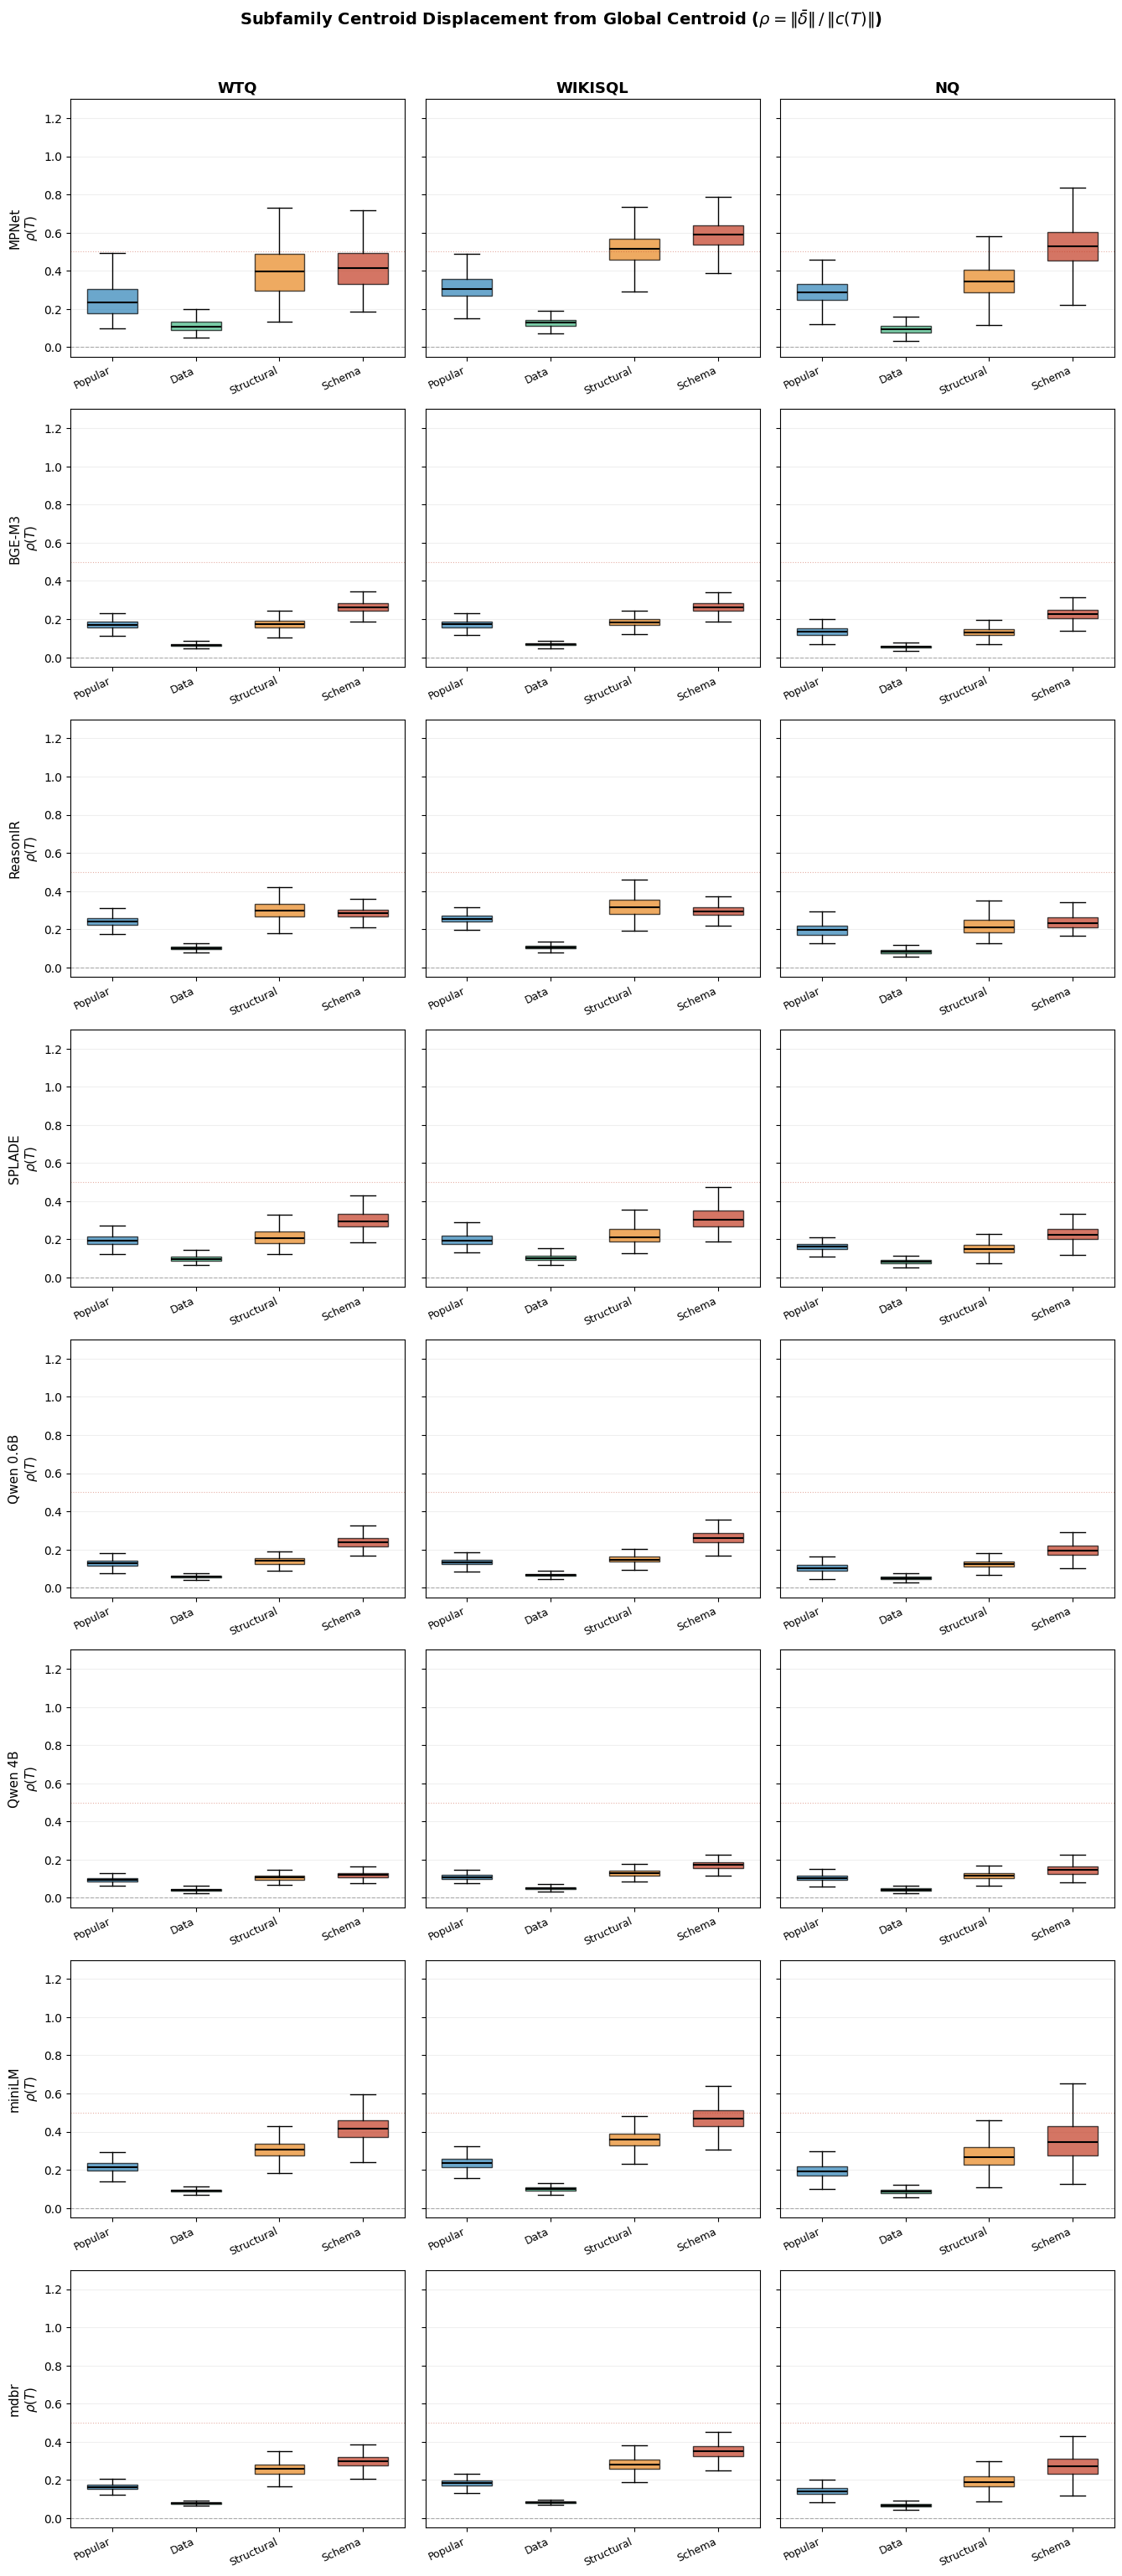

Saved fig1_subfamily_rho_boxplots.{pdf,png}


In [4]:
available_models = [m for m in MODELS if m in subfamily_rho and len(subfamily_rho[m]) > 0]
available_datasets = DATASETS  # adjust if some are missing

n_models = len(available_models)
n_datasets = len(available_datasets)

fig, axes = plt.subplots(n_models, n_datasets, figsize=(4.5 * n_datasets, 3.8 * n_models),
                         sharey='row', squeeze=False)

for row, model in enumerate(available_models):
    for col, dataset in enumerate(available_datasets):
        ax = axes[row, col]
        
        if dataset not in subfamily_rho.get(model, {}):
            ax.text(0.5, 0.5, "No data", ha='center', va='center', transform=ax.transAxes,
                    fontsize=11, color='#999')
            ax.set_xticks([])
            continue
        
        data_dict = subfamily_rho[model][dataset]
        box_data = []
        labels = []
        colors = []
        
        for fam in FAMILIES:
            key = f"rho_{fam}"
            if key in data_dict:
                arr = data_dict[key]
                box_data.append(arr)
                labels.append(fam.capitalize())
                colors.append(FAMILY_COLORS[fam])
        
        if not box_data:
            continue
        
        bp = ax.boxplot(box_data, patch_artist=True, widths=0.6,
                        showfliers=False,  # hide outliers for clarity
                        medianprops=dict(color='black', linewidth=1.5))
        
        for patch, color in zip(bp['boxes'], colors):
            patch.set_facecolor(color)
            patch.set_alpha(0.7)
        
        ax.set_xticks(range(1, len(labels) + 1))
        ax.set_xticklabels(labels, fontsize=9, rotation=25, ha='right')
        
        # Reference line at rho = 0 (perfect centering)
        ax.axhline(y=0, color='#666', linestyle='--', linewidth=0.8, alpha=0.5)
        # Reference line at rho = 0.5 (substantial displacement)
        ax.axhline(y=0.5, color='#C23B22', linestyle=':', linewidth=0.8, alpha=0.4)
        
        ax.set_ylim(-0.05, 1.3)
        ax.grid(axis='y', alpha=0.2)
        
        if col == 0:
            ax.set_ylabel(f"{MODEL_DISPLAY[model]}\n" + r"$\rho(T)$", fontsize=11)
        if row == 0:
            ax.set_title(dataset, fontsize=13, fontweight='bold')

fig.suptitle(
    r"Subfamily Centroid Displacement from Global Centroid ($\rho = \|\bar{\delta}\| \,/\, \|c(T)\|$)",
    fontsize=14, fontweight='bold', y=1.01
)
fig.tight_layout()
plt.show()
print("Saved fig1_subfamily_rho_boxplots.{pdf,png}")

## Chunk 3 — Figure 2: Median Rho Summary Heatmap

A compact heatmap showing median rho for every (model, dataset, subfamily) combination.
Lets the reader scan the full landscape at a glance.

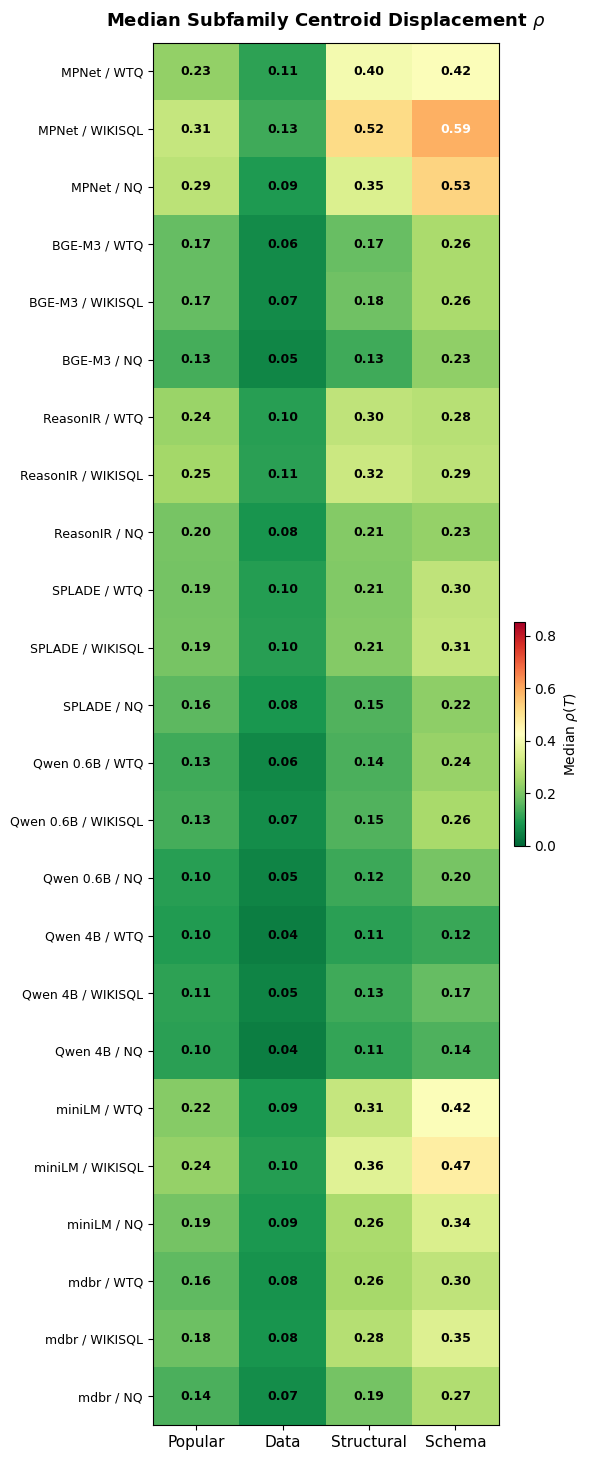

Saved fig2_rho_heatmap.{pdf,png}


In [5]:
# Build the matrix: rows = (model, dataset), cols = subfamily
row_labels = []
matrix_rows = []

for model in available_models:
    for dataset in available_datasets:
        if dataset not in subfamily_rho.get(model, {}):
            continue
        data_dict = subfamily_rho[model][dataset]
        row_vals = []
        for fam in FAMILIES:
            key = f"rho_{fam}"
            if key in data_dict:
                row_vals.append(float(np.median(data_dict[key])))
            else:
                row_vals.append(np.nan)
        matrix_rows.append(row_vals)
        row_labels.append(f"{MODEL_DISPLAY[model]} / {dataset}")

matrix = np.array(matrix_rows)

fig, ax = plt.subplots(figsize=(6, 0.55 * len(row_labels) + 1.5))

im = ax.imshow(matrix, cmap='RdYlGn_r', aspect='auto', vmin=0, vmax=0.85)

ax.set_xticks(range(len(FAMILIES)))
ax.set_xticklabels([f.capitalize() for f in FAMILIES], fontsize=11)
ax.set_yticks(range(len(row_labels)))
ax.set_yticklabels(row_labels, fontsize=9)

# Annotate cells
for i in range(matrix.shape[0]):
    for j in range(matrix.shape[1]):
        val = matrix[i, j]
        if np.isnan(val):
            continue
        text_color = 'white' if val > 0.55 else 'black'
        ax.text(j, i, f"{val:.2f}", ha='center', va='center',
                fontsize=9, fontweight='bold', color=text_color)

cbar = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.04)
cbar.set_label(r"Median $\rho(T)$", fontsize=10)

ax.set_title(r"Median Subfamily Centroid Displacement $\rho$", fontsize=13, fontweight='bold', pad=12)

fig.tight_layout()
plt.show()
print("Saved fig2_rho_heatmap.{pdf,png}")

## Chunk 4 — Figure 3: Systematic vs. Random Residual Decomposition

For each format, plot `||mu_delta_s||` (systematic) against `mean||epsilon_s||` (random).
Points above the diagonal have systematic bias dominating. Points below have random noise dominating.

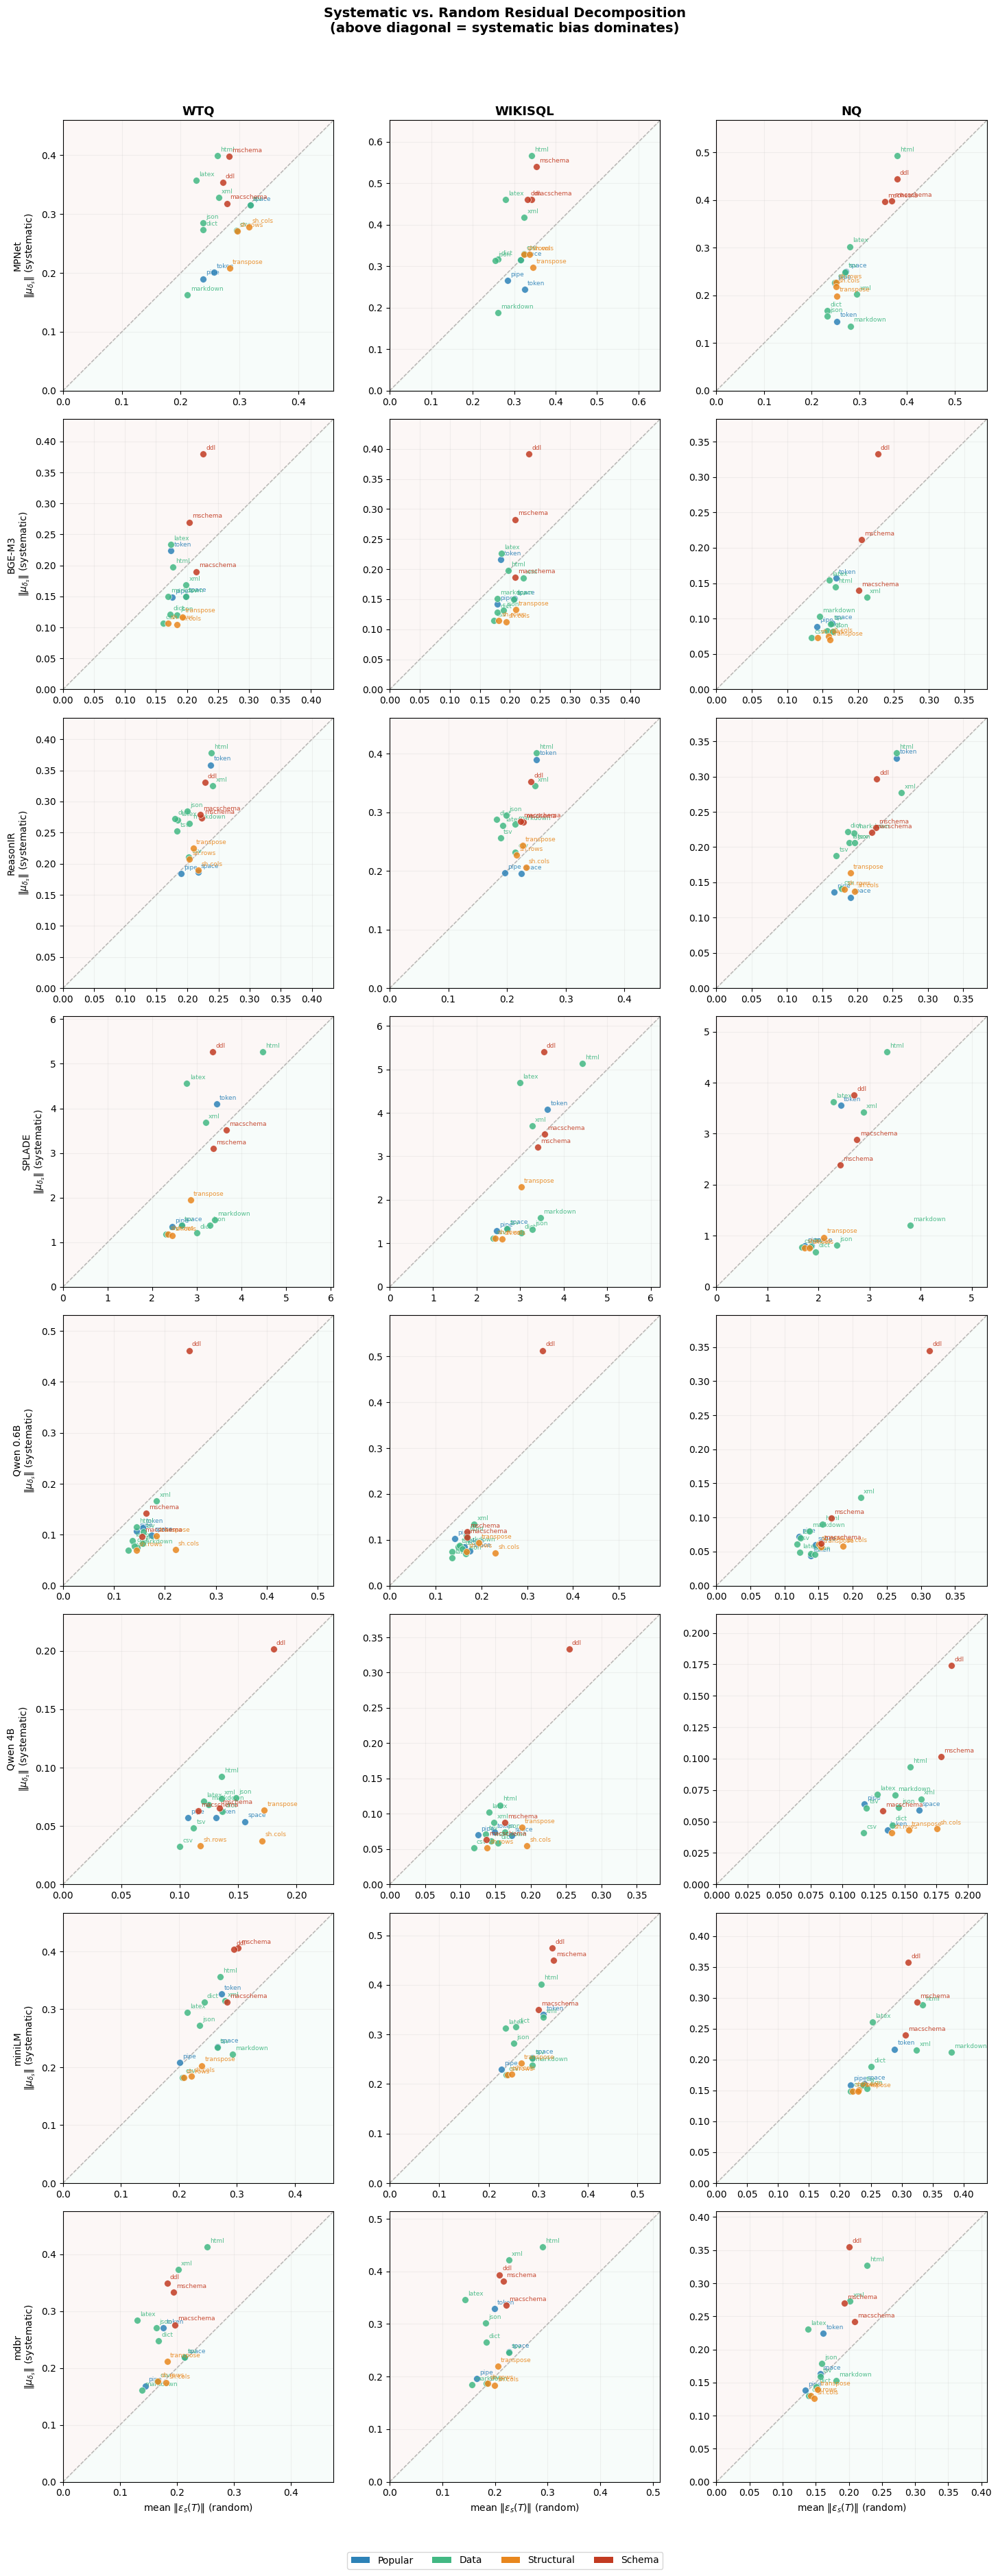

Saved fig3_systematic_vs_random.{pdf,png}


In [6]:
fig, axes = plt.subplots(n_models, n_datasets, figsize=(5 * n_datasets, 4.5 * n_models),
                         squeeze=False)

for row, model in enumerate(available_models):
    for col, dataset in enumerate(available_datasets):
        ax = axes[row, col]
        
        if dataset not in systematic_bias.get(model, {}):
            ax.text(0.5, 0.5, "No data", ha='center', va='center',
                    transform=ax.transAxes, fontsize=11, color='#999')
            continue
        
        data_dict = systematic_bias[model][dataset]
        repr_names = list(data_dict['repr_names'])
        sys_norms = data_dict['systematic_bias_norms']
        rand_norms = data_dict['random_residual_mean_norms']
        
        # Plot diagonal (ratio = 1 boundary)
        lim_max = max(np.max(sys_norms), np.max(rand_norms)) * 1.15
        ax.plot([0, lim_max], [0, lim_max], '--', color='#888', linewidth=1, alpha=0.6, zorder=1)
        
        # Fill regions
        ax.fill_between([0, lim_max], [0, lim_max], [lim_max, lim_max],
                        alpha=0.04, color='#C23B22', zorder=0)  # systematic dominates
        ax.fill_between([0, lim_max], [0, 0], [0, lim_max],
                        alpha=0.04, color='#42B883', zorder=0)  # random dominates
        
        for i, rname in enumerate(repr_names):
            fam = REPR_TO_FAMILY.get(rname.replace('chunked_', ''), "unknown")
            color = FAMILY_COLORS.get(fam, '#666')
            
            ax.scatter(rand_norms[i], sys_norms[i], c=color, s=50, zorder=3,
                       edgecolors='white', linewidth=0.5, alpha=0.85)
            
            # Label points
            label = rname.replace('_serialized', '').replace('shuffled_', 'sh.').replace('chunked_', '')
            ax.annotate(label, (rand_norms[i], sys_norms[i]),
                        fontsize=6.5, ha='left', va='bottom',
                        xytext=(3, 3), textcoords='offset points',
                        color=color, alpha=0.9)
        
        ax.set_xlim(0, lim_max)
        ax.set_ylim(0, lim_max)
        ax.set_aspect('equal')
        ax.grid(alpha=0.15)
        
        if col == 0:
            ax.set_ylabel(f"{MODEL_DISPLAY[model]}\n" + r"$\|\mu_{\delta_s}\|$ (systematic)", fontsize=10)
        if row == n_models - 1:
            ax.set_xlabel(r"mean $\|\epsilon_s(T)\|$ (random)", fontsize=10)
        if row == 0:
            ax.set_title(dataset, fontsize=13, fontweight='bold')

# Legend
legend_handles = [Patch(facecolor=FAMILY_COLORS[f], label=f.capitalize()) for f in FAMILIES]
fig.legend(handles=legend_handles, loc='lower center', ncol=4, fontsize=10,
           bbox_to_anchor=(0.5, -0.02), frameon=True, edgecolor='#ccc')

fig.suptitle("Systematic vs. Random Residual Decomposition\n"
             "(above diagonal = systematic bias dominates)",
             fontsize=14, fontweight='bold', y=1.02)
fig.tight_layout()
#plt.savefig("./savefig.png",dpi=300)
plt.show()
print("Saved fig3_systematic_vs_random.{pdf,png}")

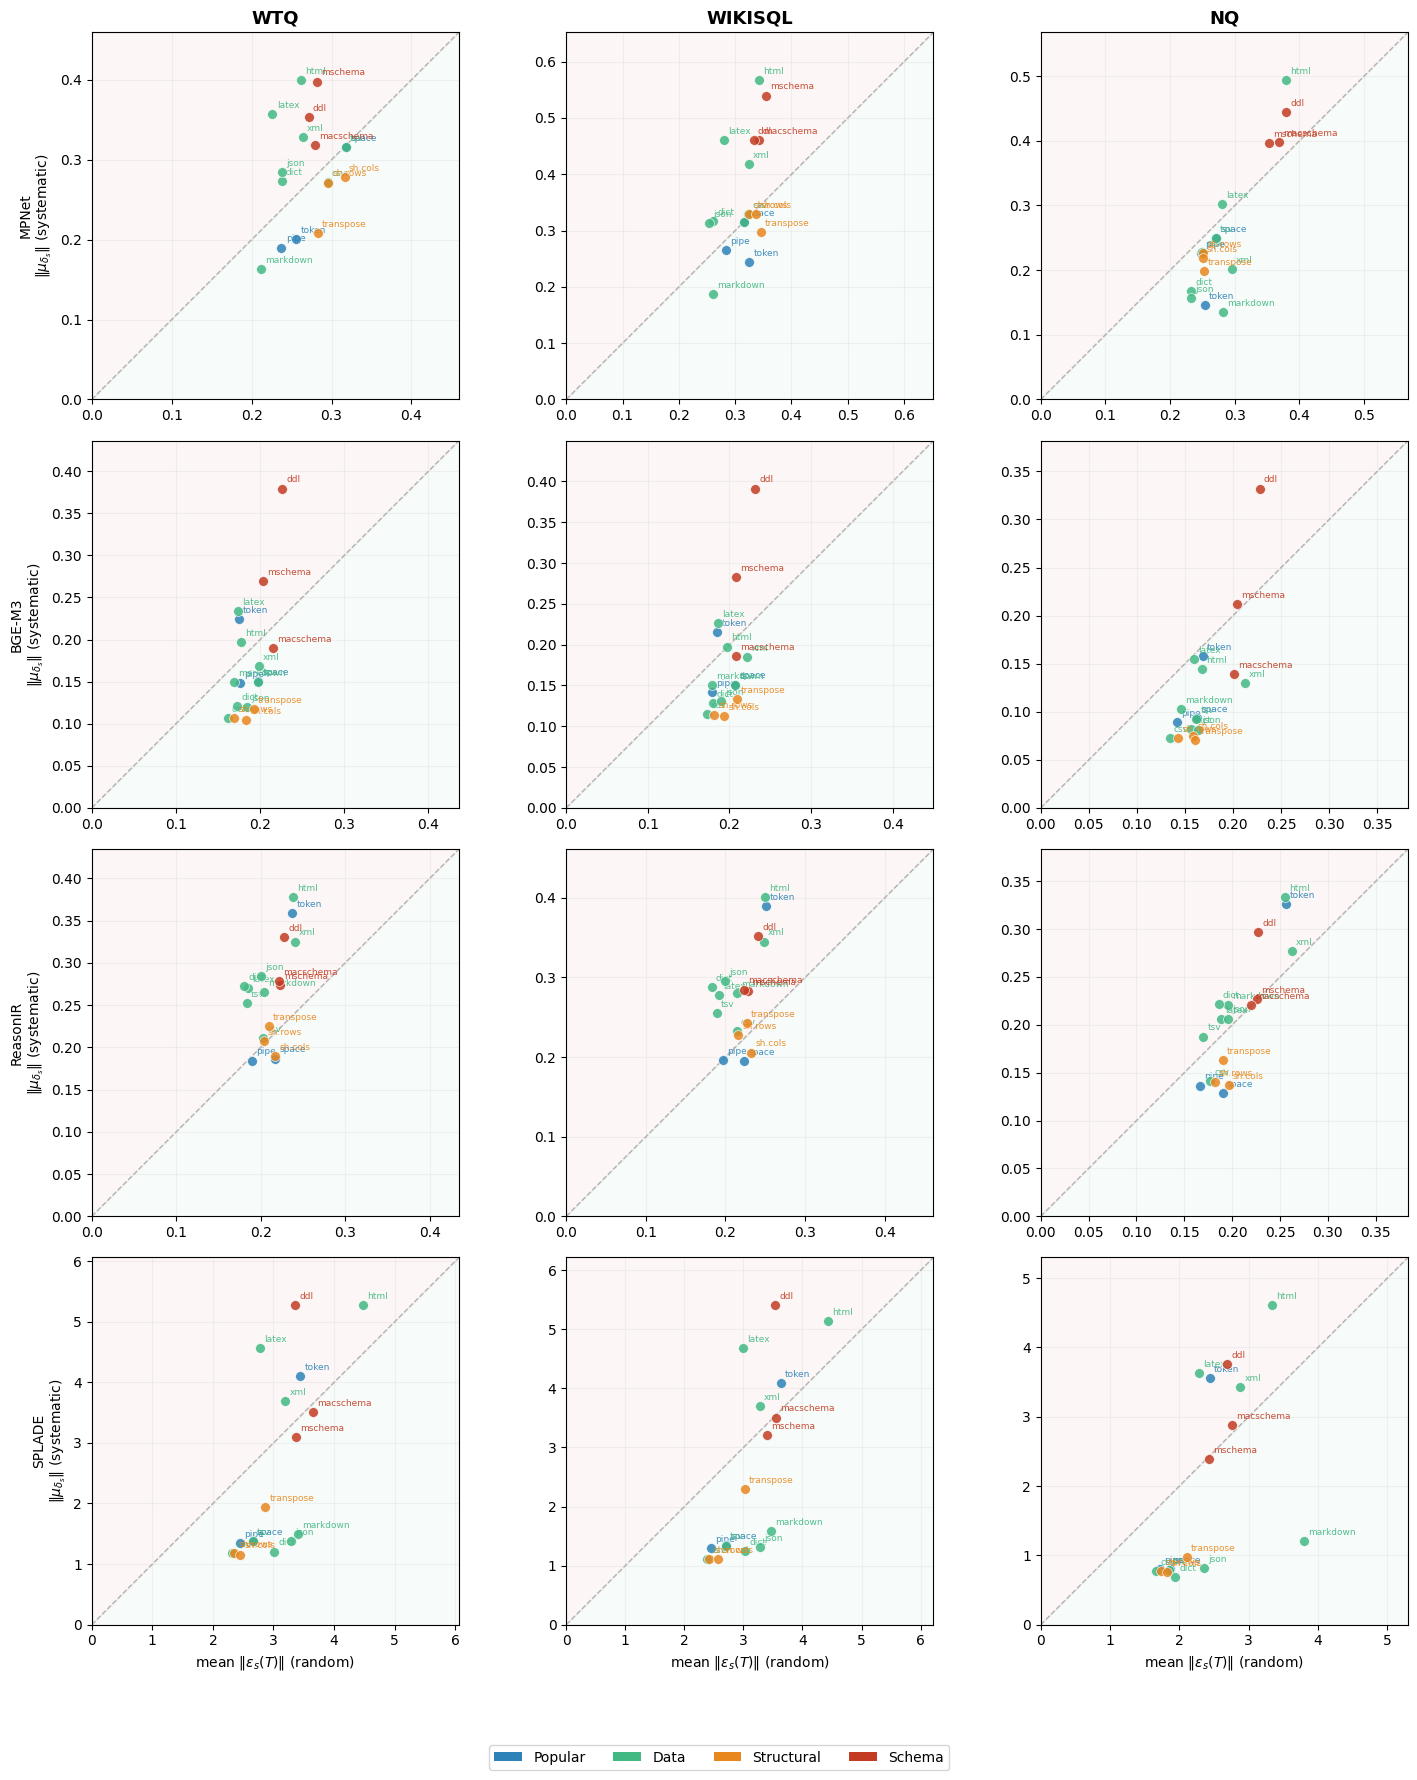

Figure 1 contains 4 models


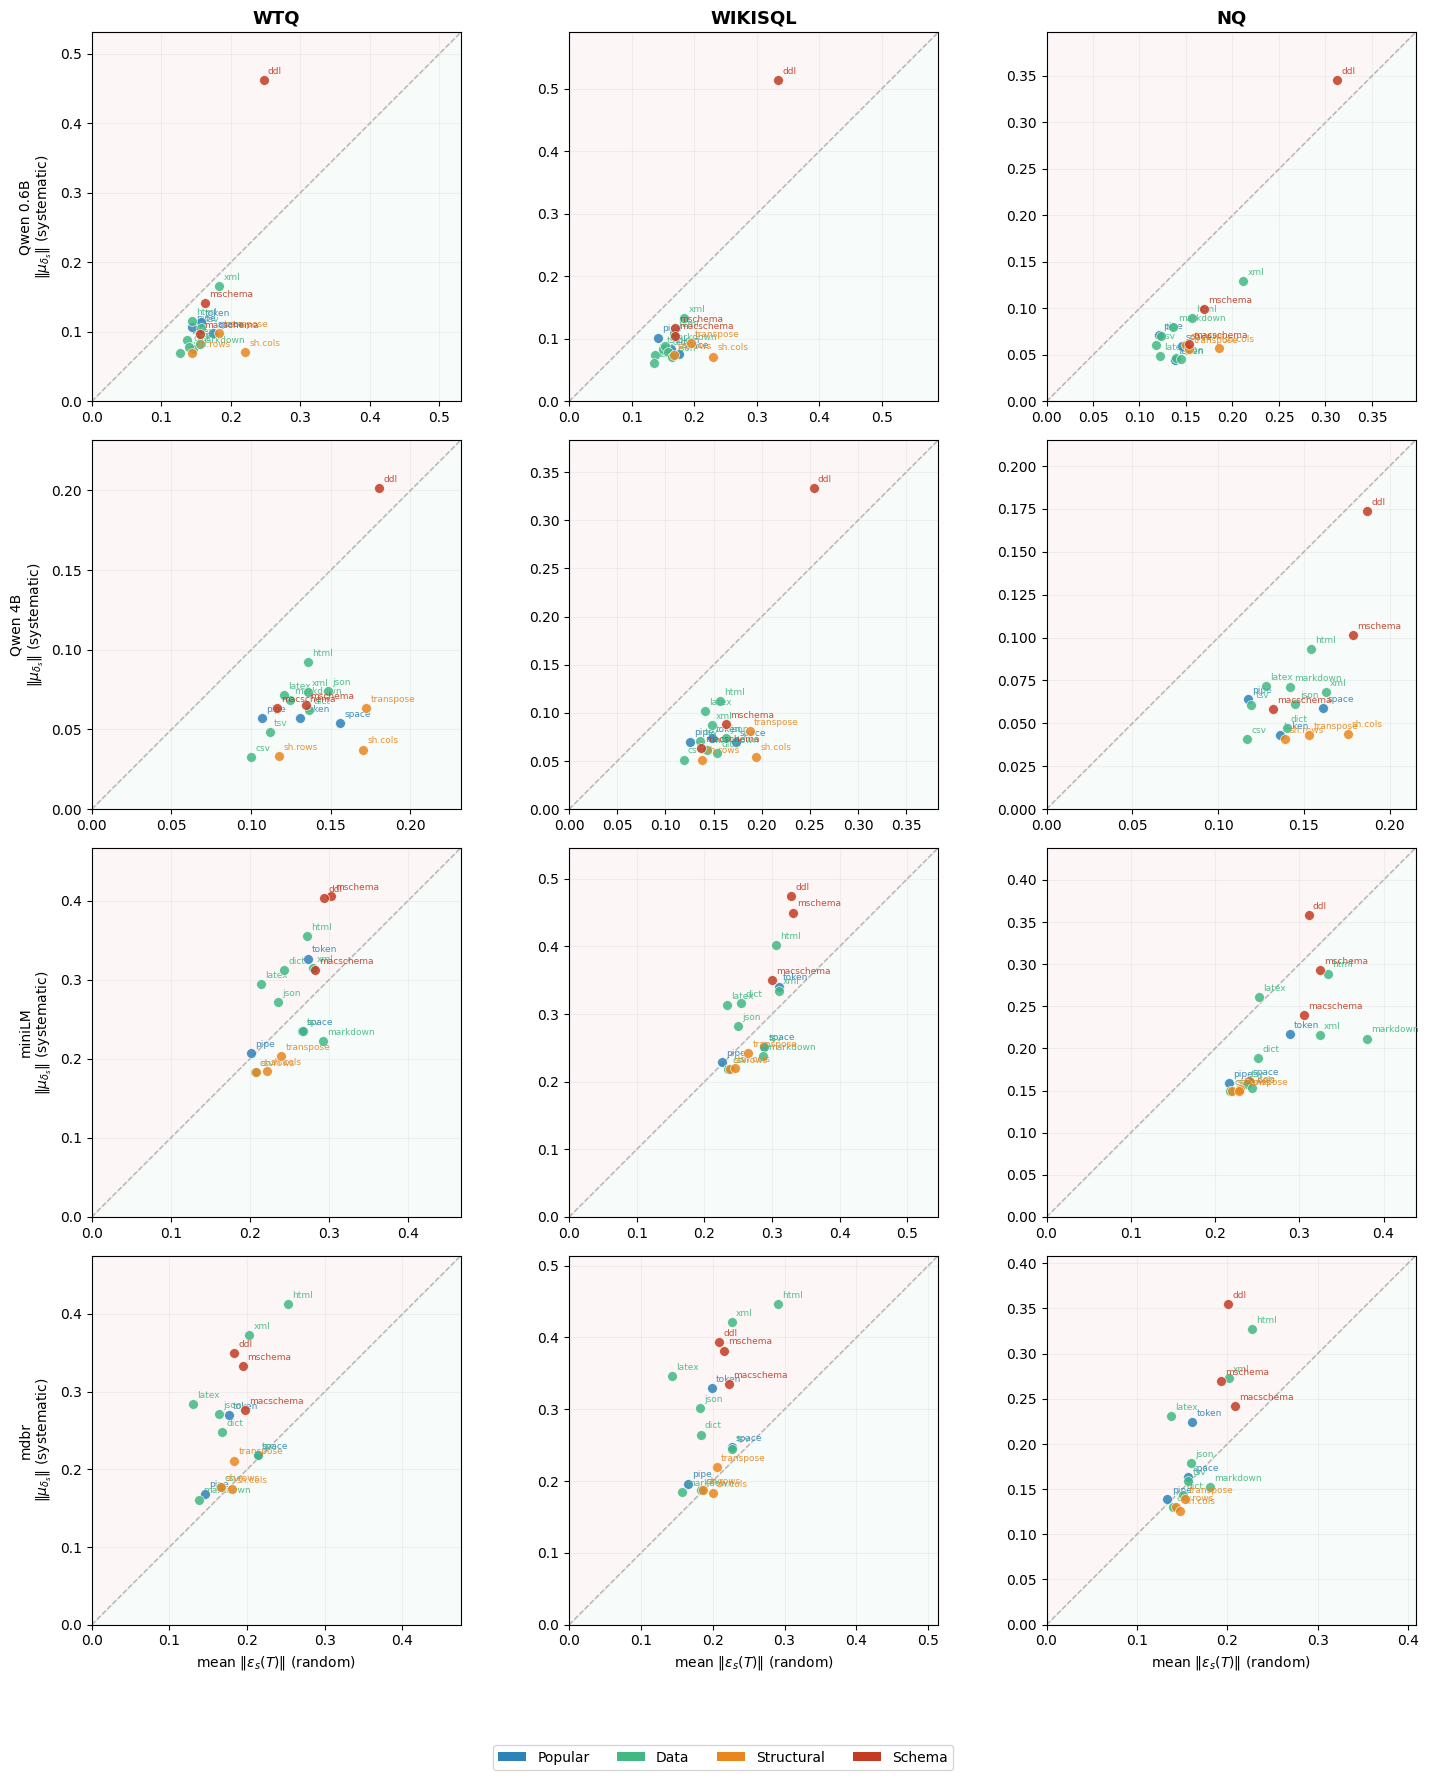

Figure 2 contains 4 models


In [17]:
# Split models into two approximately equal groups
model_groups = np.array_split(available_models, 2)

for fig_idx, models_subset in enumerate(model_groups, start=1):
    models_subset = list(models_subset)
    n_rows = len(models_subset)

    fig, axes = plt.subplots(n_rows, n_datasets, figsize=(5 * n_datasets, 4.5 * n_rows), squeeze=False)

    for row, model in enumerate(models_subset):
        for col, dataset in enumerate(available_datasets):
            ax = axes[row, col]

            if dataset not in systematic_bias.get(model, {}):
                ax.text(0.5, 0.5, "No data", ha="center", va="center", transform=ax.transAxes, fontsize=11, color="#999")
                ax.set_axis_off()
                continue

            data_dict = systematic_bias[model][dataset]
            repr_names = list(data_dict["repr_names"])
            sys_norms = data_dict["systematic_bias_norms"]
            rand_norms = data_dict["random_residual_mean_norms"]

            # Diagonal boundary
            lim_max = max(np.max(sys_norms), np.max(rand_norms)) * 1.15
            ax.plot([0, lim_max], [0, lim_max], "--", color="#888", linewidth=1, alpha=0.6, zorder=1)

            # Dominance regions
            ax.fill_between([0, lim_max], [0, lim_max], [lim_max, lim_max], alpha=0.04, color="#C23B22", zorder=0)
            ax.fill_between([0, lim_max], [0, 0], [0, lim_max], alpha=0.04, color="#42B883", zorder=0)

            for i, rname in enumerate(repr_names):
                fam = REPR_TO_FAMILY.get(rname.replace("chunked_", ""), "unknown")
                color = FAMILY_COLORS.get(fam, "#666")

                ax.scatter(rand_norms[i], sys_norms[i], c=color, s=50, zorder=3, edgecolors="white", linewidth=0.5, alpha=0.85)

                label = rname.replace("_serialized", "").replace("shuffled_", "sh.").replace("chunked_", "")
                ax.annotate(label, (rand_norms[i], sys_norms[i]), fontsize=6.5, ha="left", va="bottom", xytext=(3, 3), textcoords="offset points", color=color, alpha=0.9)

            ax.set_xlim(0, lim_max)
            ax.set_ylim(0, lim_max)
            ax.set_aspect("equal")
            ax.grid(alpha=0.15)

            if col == 0:
                ax.set_ylabel(f"{MODEL_DISPLAY[model]}\n" + r"$\|\mu_{\delta_s}\|$ (systematic)", fontsize=10)

            if row == n_rows - 1:
                ax.set_xlabel(r"mean $\|\epsilon_s(T)\|$ (random)", fontsize=10)

            if row == 0:
                ax.set_title(dataset, fontsize=13, fontweight="bold")

    legend_handles = [Patch(facecolor=FAMILY_COLORS[f], label=f.capitalize()) for f in FAMILIES]
    fig.legend(handles=legend_handles, loc="lower center", ncol=4, fontsize=10, bbox_to_anchor=(0.5, -0.01), frameon=True, edgecolor="#ccc")

    #fig.suptitle(
    #    "Systematic vs. Random Residual Decomposition\n"
    #    "(above diagonal = systematic bias dominates)",
    #    fontsize=14,
    #    fontweight="bold",
    #    y=1.01
    #)

    fig.tight_layout(rect=[0, 0.04, 1, 0.98])

    # plt.savefig(f"./fig3_systematic_vs_random_{fig_idx}.pdf", bbox_inches="tight")
    # plt.savefig(f"./fig3_systematic_vs_random_{fig_idx}.png", dpi=300, bbox_inches="tight")

    plt.show()

    print(f"Figure {fig_idx} contains {len(models_subset)} models")

## Chunk 5 — Figure 4: Systematic/Random Ratio Bar Chart

Grouped bar chart of `||mu_delta_s|| / mean||epsilon_s||` per format,
aggregated across datasets for each retriever. Formats with ratio > 1
violate the centering assumption.

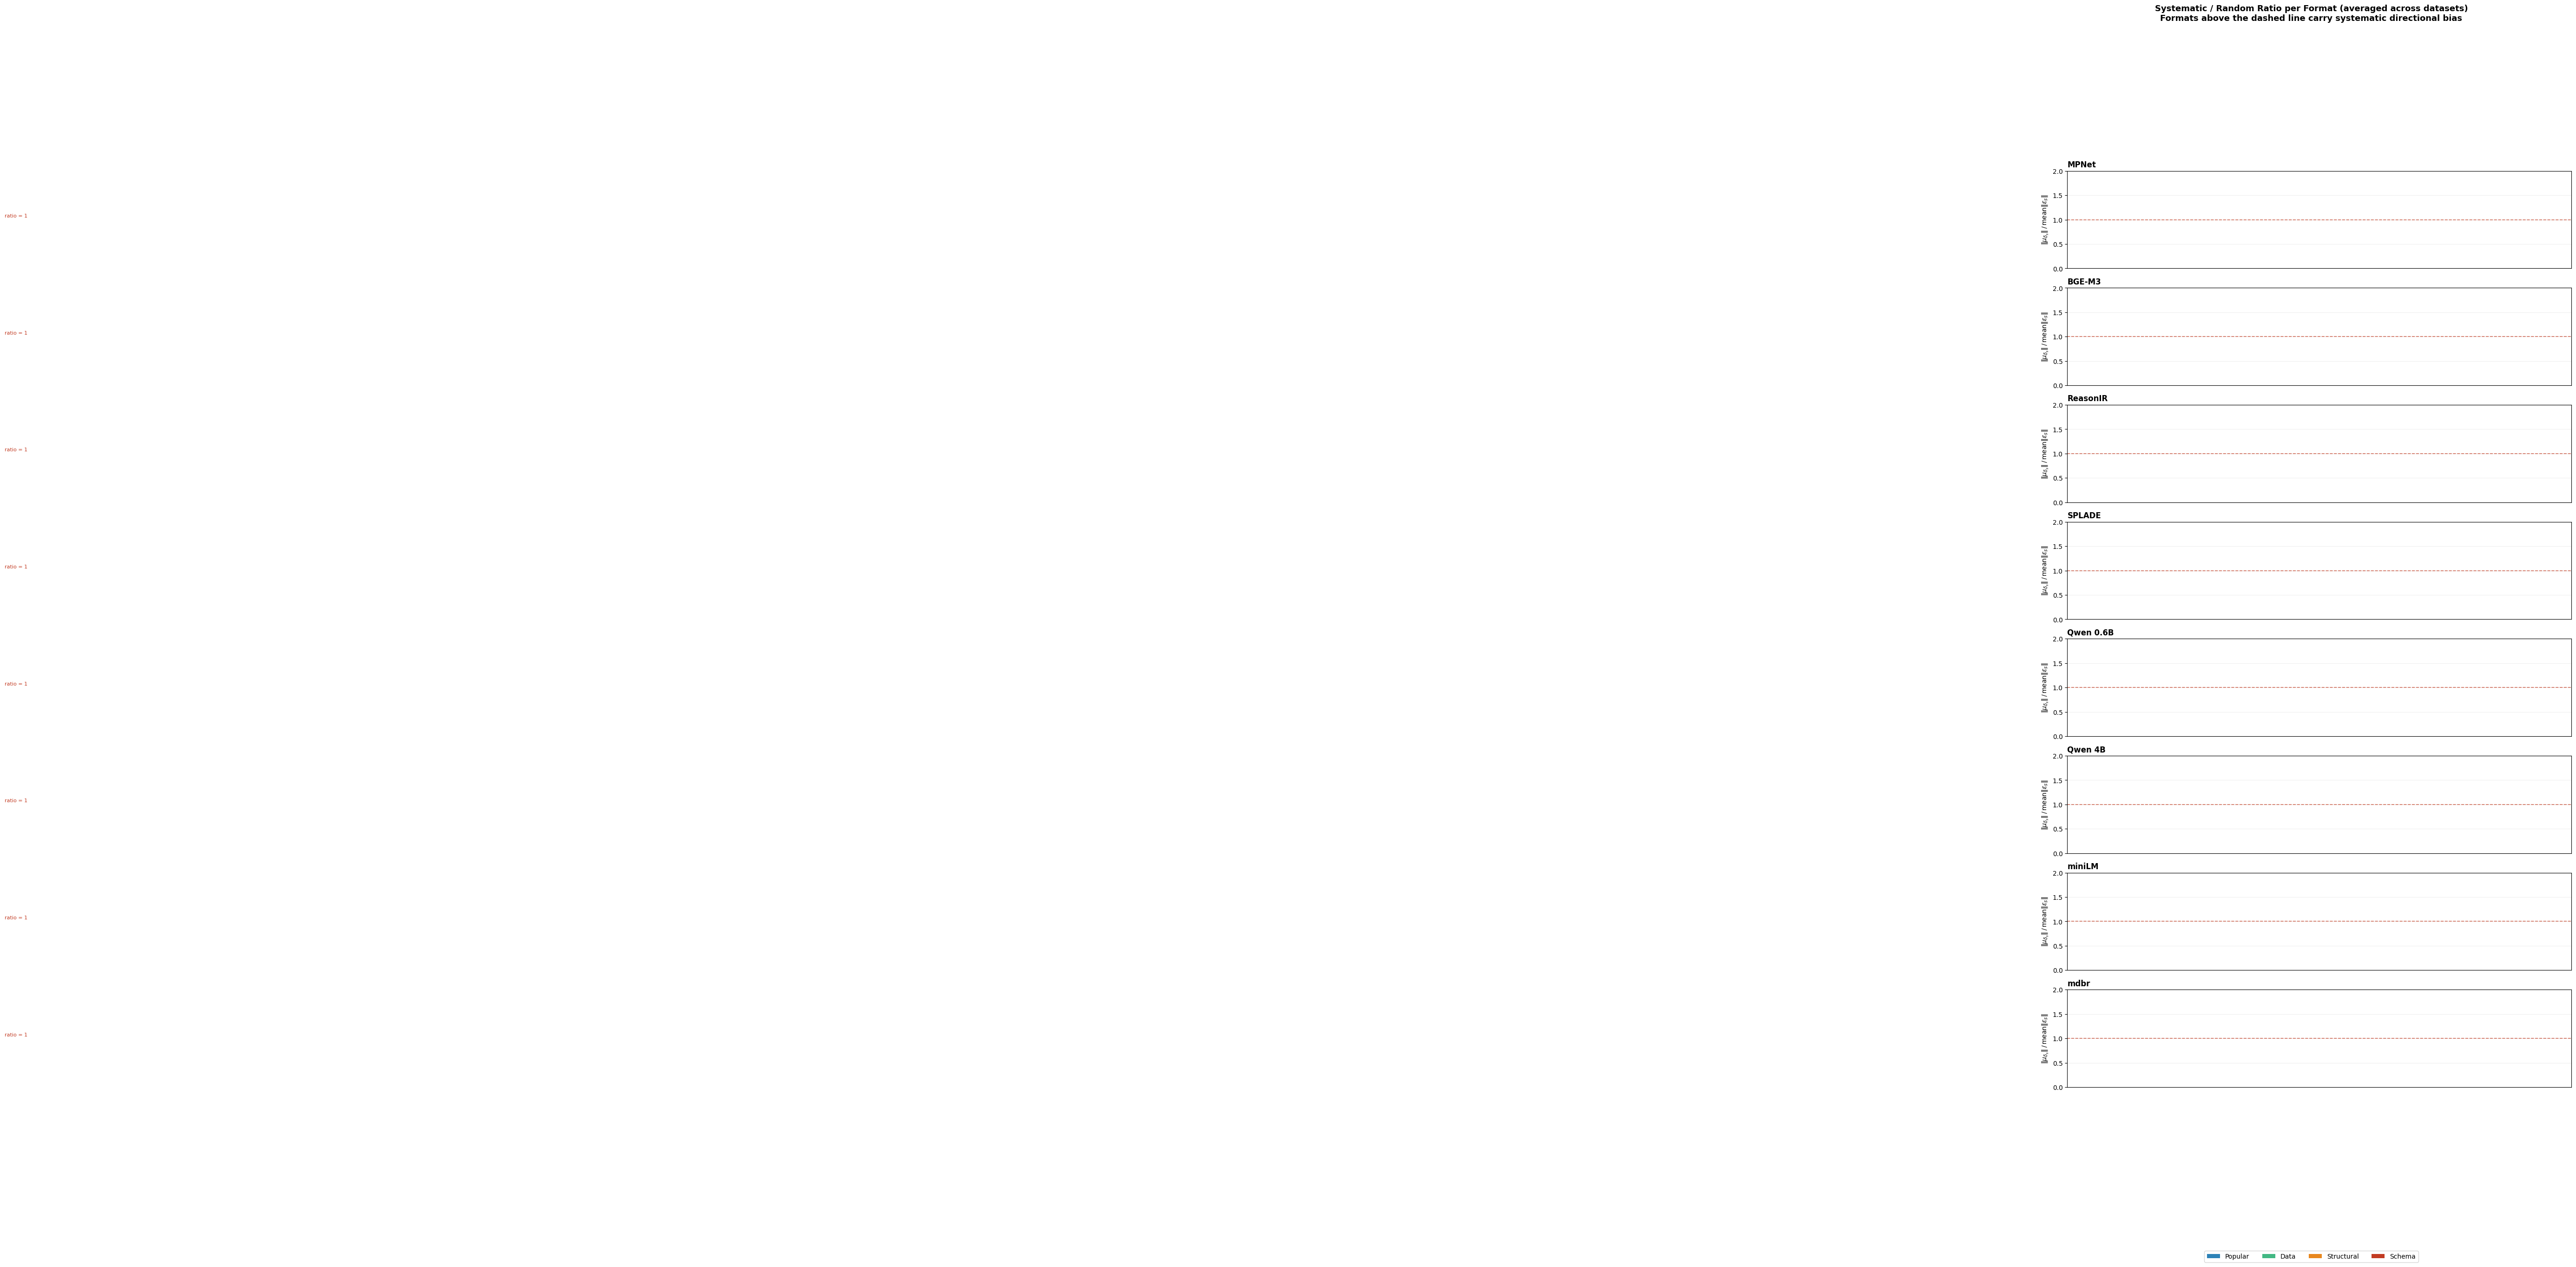

Saved fig4_sys_rand_ratio_bars.{pdf,png}


In [8]:
# Compute mean ratio across datasets for each (model, repr)
ALL_REPRS = [r for fam in FAMILIES for r in FAMILY_MEMBERS[fam]]

fig, axes = plt.subplots(len(available_models), 1,
                         figsize=(14, 3.2 * len(available_models)),
                         sharex=True, squeeze=False)

for row, model in enumerate(available_models):
    ax = axes[row, 0]
    
    # Gather ratios across datasets
    repr_ratios = defaultdict(list)
    for dataset in available_datasets:
        if dataset not in systematic_bias.get(model, {}):
            continue
        data_dict = systematic_bias[model][dataset]
        repr_names = list(data_dict['repr_names'])
        sys_norms = data_dict['systematic_bias_norms']
        rand_norms = data_dict['random_residual_mean_norms']
        for i, rname in enumerate(repr_names):
            if rand_norms[i] > 1e-10:
                repr_ratios[rname].append(sys_norms[i] / rand_norms[i])
    
    # Order by family membership
    ordered_reprs = [r for r in ALL_REPRS if r in repr_ratios]
    mean_ratios = [np.mean(repr_ratios[r]) for r in ordered_reprs]
    
    bar_colors = [FAMILY_COLORS[REPR_TO_FAMILY[r]] for r in ordered_reprs]
    short_labels = [r.replace('_serialized', '').replace('shuffled_', 'sh.') for r in ordered_reprs]
    
    bars = ax.bar(range(len(ordered_reprs)), mean_ratios, color=bar_colors, alpha=0.8,
                  edgecolor='white', linewidth=0.5)
    
    # Reference line at ratio = 1
    ax.axhline(y=1.0, color='#C23B22', linestyle='--', linewidth=1.2, alpha=0.7)
    ax.text(len(ordered_reprs) - 0.5, 1.03, 'ratio = 1', fontsize=8, color='#C23B22',
            ha='right', va='bottom')
    
    ax.set_xticks(range(len(ordered_reprs)))
    if row == len(available_models) - 1:
        ax.set_xticklabels(short_labels, fontsize=8, rotation=45, ha='right')
    ax.set_ylabel(r"$\|\mu_{\delta_s}\| \,/\, \mathrm{mean}\|\epsilon_s\|$", fontsize=10)
    ax.set_title(MODEL_DISPLAY[model], fontsize=12, fontweight='bold', loc='left')
    ax.grid(axis='y', alpha=0.2)
    ax.set_ylim(0, max(mean_ratios) * 1.15 if mean_ratios else 2.0)

# Family legend
legend_handles = [Patch(facecolor=FAMILY_COLORS[f], label=f.capitalize()) for f in FAMILIES]
fig.legend(handles=legend_handles, loc='lower center', ncol=4, fontsize=10,
           bbox_to_anchor=(0.5, -0.04), frameon=True, edgecolor='#ccc')

fig.suptitle("Systematic / Random Ratio per Format (averaged across datasets)\n"
             "Formats above the dashed line carry systematic directional bias",
             fontsize=13, fontweight='bold', y=1.02)
fig.tight_layout()
plt.show()
print("Saved fig4_sys_rand_ratio_bars.{pdf,png}")

## Chunk 6 — Figure 5: Cross-Subfamily Pairwise Distance Heatmaps

For each retriever, show the mean pairwise distance between subfamily centroids.
Large values mean those subfamilies occupy geometrically distant regions.

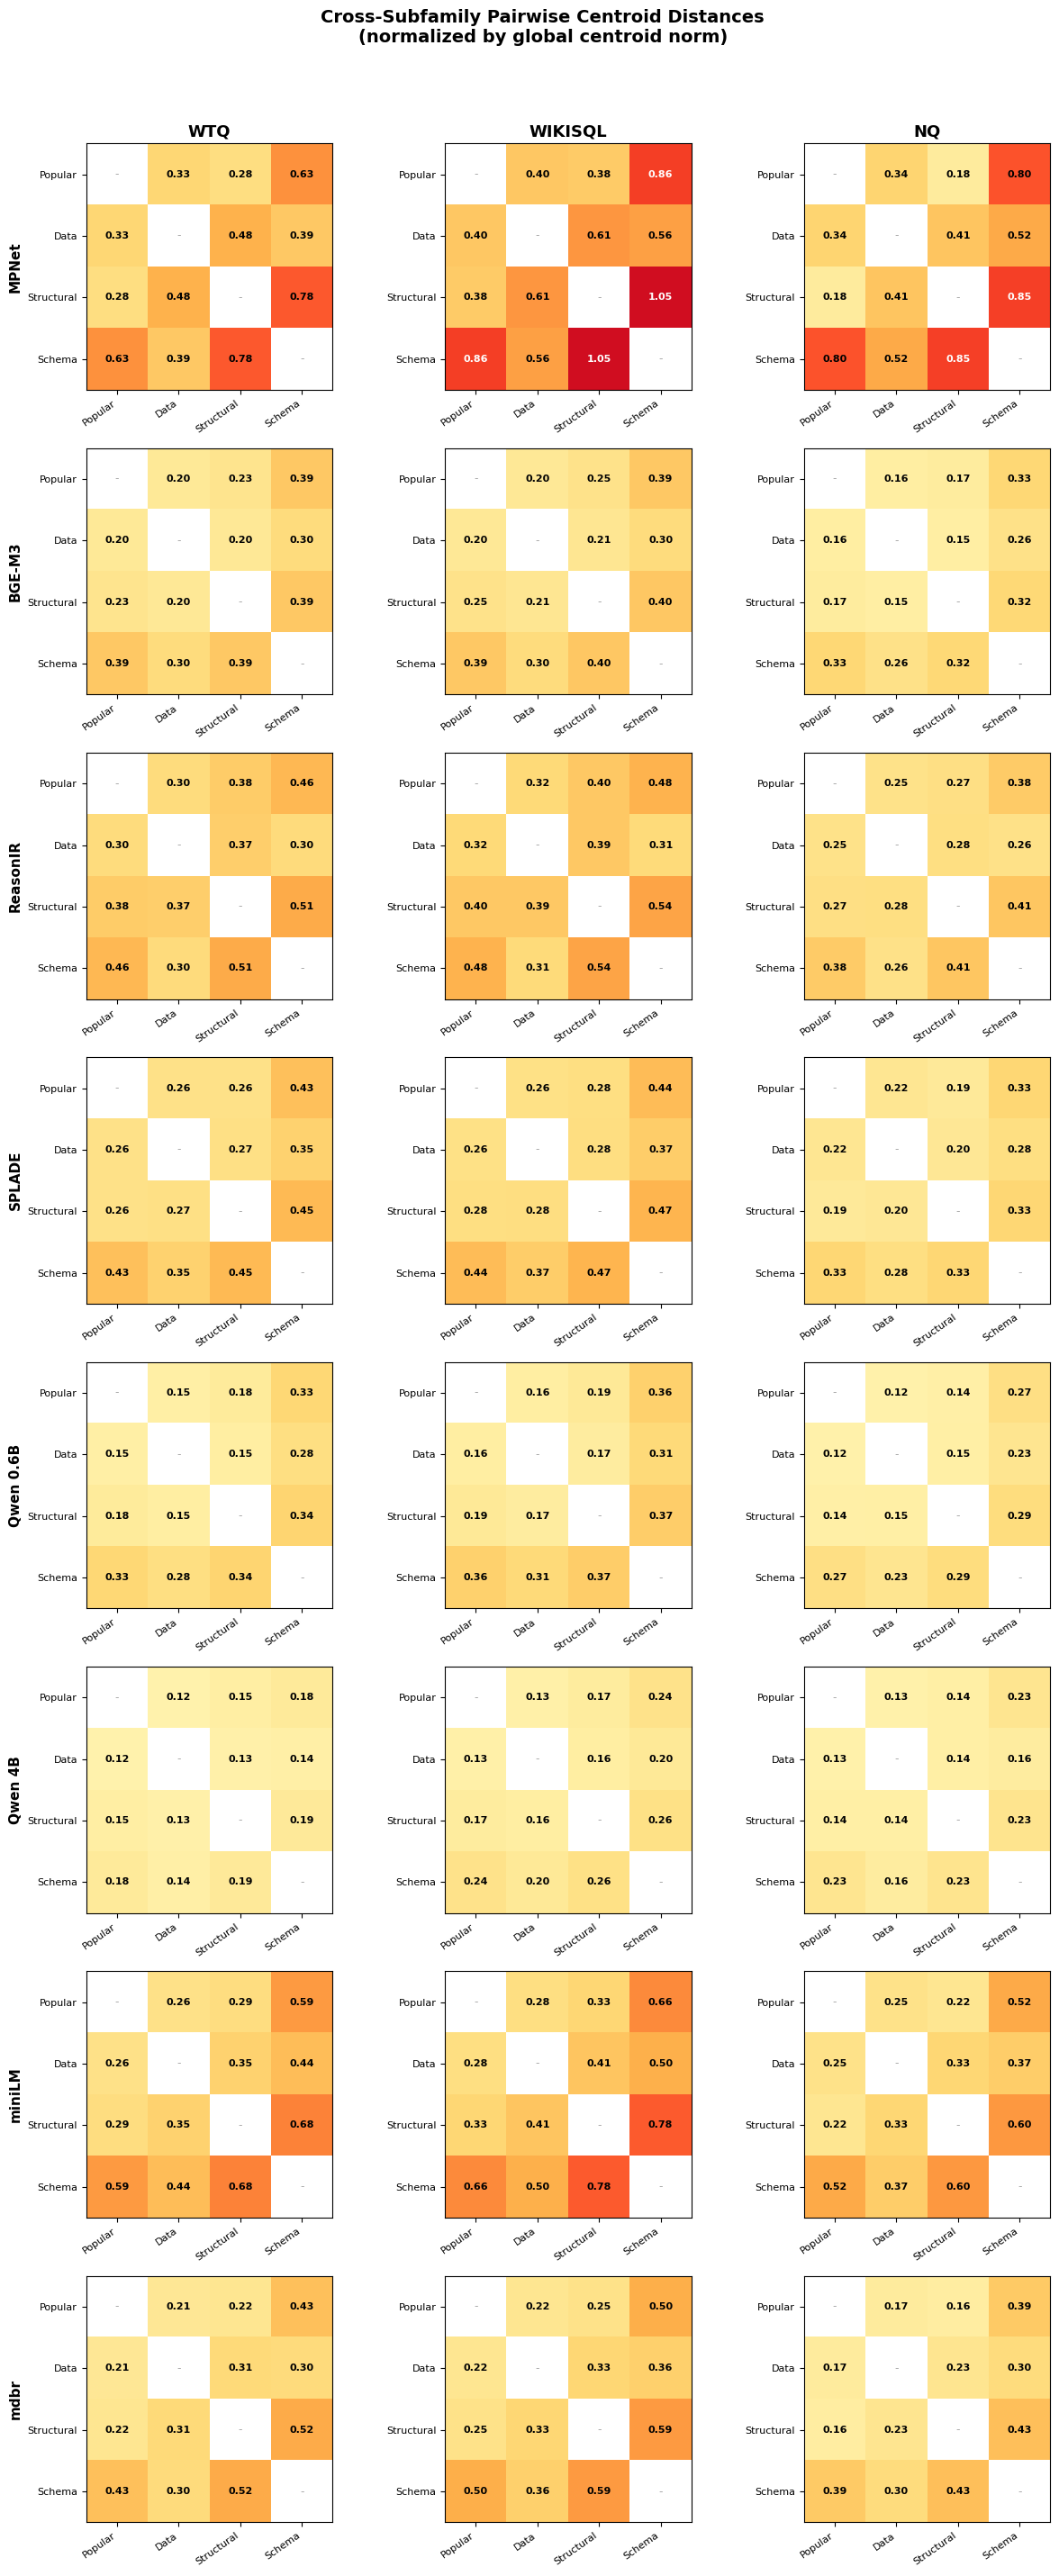

Saved fig5_pairwise_subfamily_heatmaps.{pdf,png}


In [9]:
fig, axes = plt.subplots(n_models, n_datasets, figsize=(4.2 * n_datasets, 3.5 * n_models),
                         squeeze=False)

for row, model in enumerate(available_models):
    for col, dataset in enumerate(available_datasets):
        ax = axes[row, col]
        
        if dataset not in pairwise_dist.get(model, {}):
            ax.text(0.5, 0.5, "No data", ha='center', va='center',
                    transform=ax.transAxes, fontsize=11, color='#999')
            ax.set_xticks([])
            ax.set_yticks([])
            continue
        
        data_dict = pairwise_dist[model][dataset]
        pw = data_dict['pairwise_distances']  # (n_tables, n_fam, n_fam)
        fam_names = list(data_dict['family_names'])
        
        mean_pw = pw.mean(axis=0)
        
        # Mask the diagonal
        mask = np.eye(len(fam_names), dtype=bool)
        display_matrix = np.where(mask, np.nan, mean_pw)
        
        im = ax.imshow(display_matrix, cmap='YlOrRd', aspect='equal',
                       vmin=0, vmax=1.3)
        
        labels = [f.capitalize() for f in fam_names]
        ax.set_xticks(range(len(labels)))
        ax.set_xticklabels(labels, fontsize=8, rotation=35, ha='right')
        ax.set_yticks(range(len(labels)))
        ax.set_yticklabels(labels, fontsize=8)
        
        # Annotate
        for i in range(len(fam_names)):
            for j in range(len(fam_names)):
                if i == j:
                    ax.text(j, i, "-", ha='center', va='center', fontsize=9, color='#aaa')
                else:
                    val = mean_pw[i, j]
                    text_color = 'white' if val > 0.8 else 'black'
                    ax.text(j, i, f"{val:.2f}", ha='center', va='center',
                            fontsize=8, fontweight='bold', color=text_color)
        
        if col == 0:
            ax.set_ylabel(MODEL_DISPLAY[model], fontsize=11, fontweight='bold')
        if row == 0:
            ax.set_title(dataset, fontsize=13, fontweight='bold')

fig.suptitle("Cross-Subfamily Pairwise Centroid Distances\n"
             "(normalized by global centroid norm)",
             fontsize=14, fontweight='bold', y=1.02)
fig.tight_layout()
plt.show()
print("Saved fig5_pairwise_subfamily_heatmaps.{pdf,png}")

## Chunk 7 — Figure 6: Within-Subfamily Spread Comparison

Grouped bar chart showing how scattered embeddings are around their own
subfamily centroid. High spread = formats within the subfamily disagree with each other.

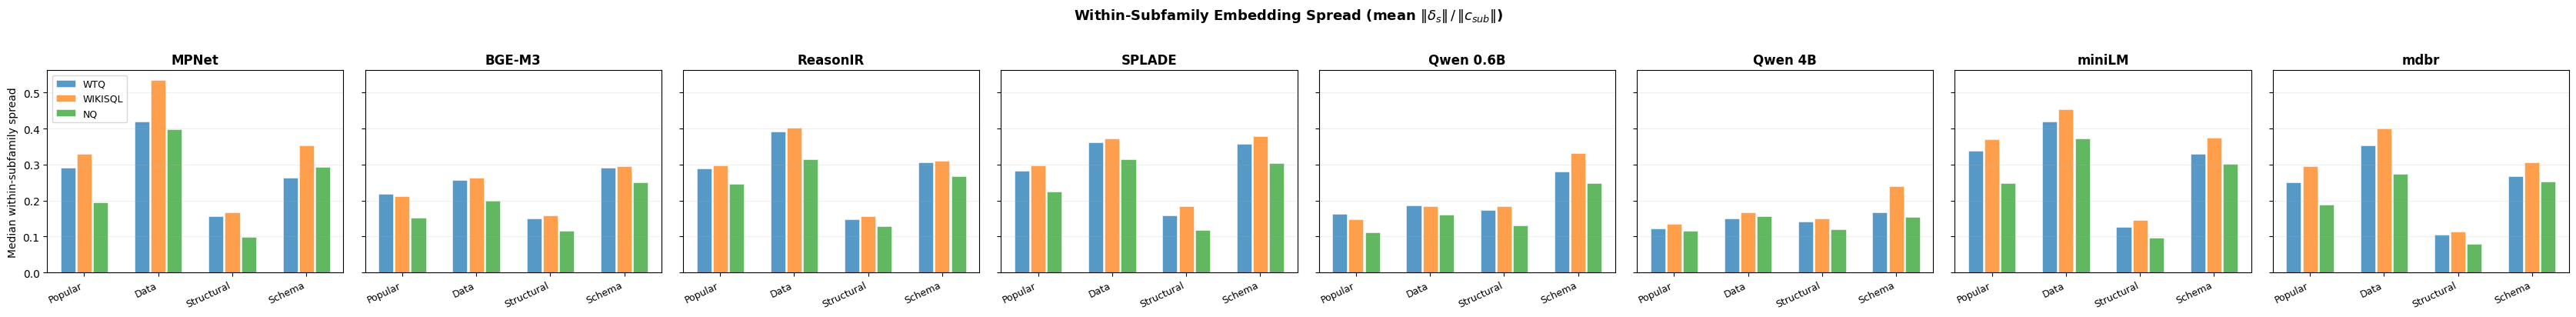

Saved fig6_within_subfamily_spread.{pdf,png}


In [10]:
fig, axes = plt.subplots(1, n_models, figsize=(4.2 * n_models, 4), sharey=True, squeeze=False)

bar_width = 0.22
x_base = np.arange(len(FAMILIES))

for idx, model in enumerate(available_models):
    ax = axes[0, idx]
    
    for d_idx, dataset in enumerate(available_datasets):
        if dataset not in within_spread.get(model, {}):
            continue
        data_dict = within_spread[model][dataset]
        
        medians = []
        for fam in FAMILIES:
            key = f"spread_{fam}"
            if key in data_dict:
                medians.append(float(np.median(data_dict[key])))
            else:
                medians.append(0)
        
        offset = (d_idx - (n_datasets - 1) / 2) * bar_width
        bars = ax.bar(x_base + offset, medians, bar_width * 0.9,
                      label=dataset if idx == 0 else None,
                      color=f"C{d_idx}", alpha=0.75, edgecolor='white', linewidth=0.5)
    
    ax.set_xticks(x_base)
    ax.set_xticklabels([f.capitalize() for f in FAMILIES], fontsize=9, rotation=25, ha='right')
    ax.set_title(MODEL_DISPLAY[model], fontsize=12, fontweight='bold')
    ax.grid(axis='y', alpha=0.2)
    if idx == 0:
        ax.set_ylabel("Median within-subfamily spread", fontsize=10)

axes[0, 0].legend(fontsize=9, loc='upper left')

fig.suptitle(r"Within-Subfamily Embedding Spread (mean $\|\delta_s\| \,/\, \|c_{sub}\|$)",
             fontsize=13, fontweight='bold', y=1.02)
fig.tight_layout()
plt.show()
print("Saved fig6_within_subfamily_spread.{pdf,png}")

## Chunk 8 — Figure 7: Model Comparison - Median Rho Across Retrievers

For each subfamily, compare how different retrievers handle the centering assumption.
This directly explains why the adapter works better for some models than others.

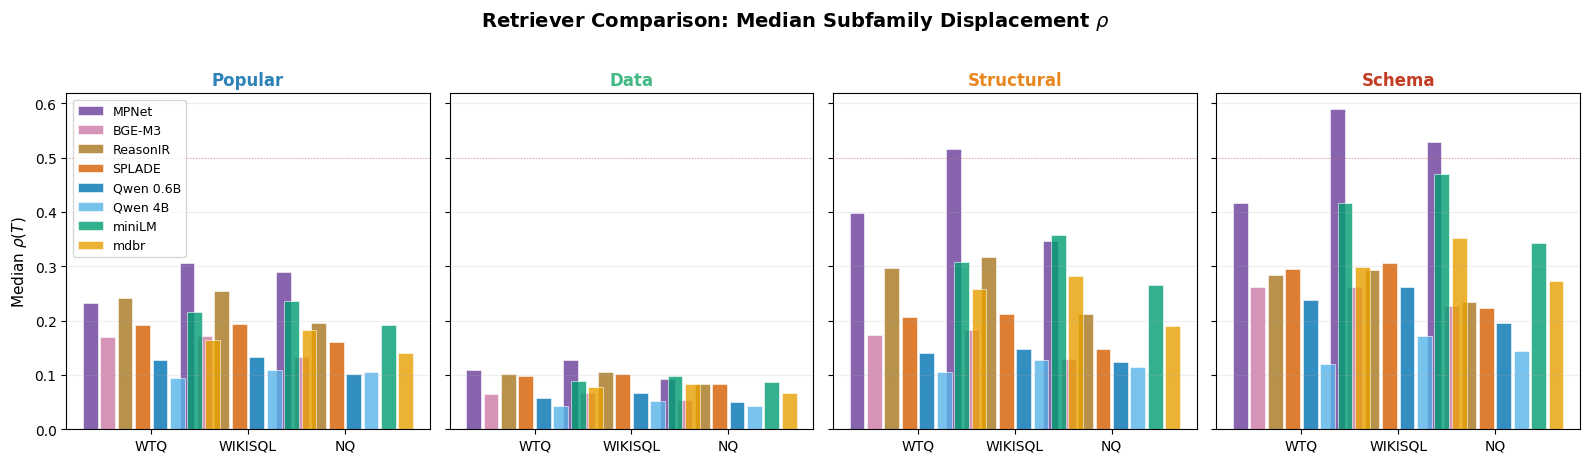

Saved fig7_model_comparison_rho.{pdf,png}


In [11]:
fig, axes = plt.subplots(1, len(FAMILIES), figsize=(4 * len(FAMILIES), 4.5),
                         sharey=True, squeeze=False)

bar_width = 0.18
x_base = np.arange(n_datasets)

for f_idx, fam in enumerate(FAMILIES):
    ax = axes[0, f_idx]
    
    for m_idx, model in enumerate(available_models):
        medians = []
        for dataset in available_datasets:
            if dataset in subfamily_rho.get(model, {}):
                key = f"rho_{fam}"
                data_dict = subfamily_rho[model][dataset]
                if key in data_dict:
                    medians.append(float(np.median(data_dict[key])))
                else:
                    medians.append(0)
            else:
                medians.append(0)
        
        offset = (m_idx - (len(available_models) - 1) / 2) * bar_width
        ax.bar(x_base + offset, medians, bar_width * 0.85,
               label=MODEL_DISPLAY[model] if f_idx == 0 else None,
               color=MODEL_COLORS[model], alpha=0.8,
               edgecolor='white', linewidth=0.5)
    
    ax.set_xticks(x_base)
    ax.set_xticklabels(available_datasets, fontsize=10)
    ax.set_title(fam.capitalize(), fontsize=12, fontweight='bold',
                 color=FAMILY_COLORS[fam])
    ax.grid(axis='y', alpha=0.2)
    ax.axhline(y=0.5, color='#C23B22', linestyle=':', linewidth=0.8, alpha=0.4)
    if f_idx == 0:
        ax.set_ylabel(r"Median $\rho(T)$", fontsize=11)

axes[0, 0].legend(fontsize=9, loc='upper left')

fig.suptitle(r"Retriever Comparison: Median Subfamily Displacement $\rho$",
             fontsize=14, fontweight='bold', y=1.02)
fig.tight_layout()
plt.show()
print("Saved fig7_model_comparison_rho.{pdf,png}")

## Chunk 9 — Summary Statistics Table

Print a LaTeX-ready summary table for inclusion in the paper.

In [12]:
print("="*90)
print(f"{'Model':<12} {'Dataset':<10} {'Popular':>10} {'Data':>10} {'Structural':>12} {'Schema':>10}")
print("="*90)

for model in available_models:
    for dataset in available_datasets:
        if dataset not in subfamily_rho.get(model, {}):
            continue
        data_dict = subfamily_rho[model][dataset]
        vals = []
        for fam in FAMILIES:
            key = f"rho_{fam}"
            if key in data_dict:
                vals.append(f"{np.median(data_dict[key]):.3f}")
            else:
                vals.append("  ---")
        print(f"{MODEL_DISPLAY[model]:<12} {dataset:<10} {vals[0]:>10} {vals[1]:>10} {vals[2]:>12} {vals[3]:>10}")
    print("-"*90)

print()
print("LaTeX table (median rho values):")
print()
print(r"\begin{table}[t]")
print(r"\centering")
print(r"\caption{Median subfamily centroid displacement $\rho(T)$ across retrievers and datasets.}")
print(r"\label{tab:residual_rho}")
print(r"\begin{tabular}{llcccc}")
print(r"\toprule")
print(r"Model & Dataset & Popular & Data & Structural & Schema \\")
print(r"\midrule")

for model in available_models:
    first_row = True
    for dataset in available_datasets:
        if dataset not in subfamily_rho.get(model, {}):
            continue
        data_dict = subfamily_rho[model][dataset]
        vals = []
        for fam in FAMILIES:
            key = f"rho_{fam}"
            if key in data_dict:
                v = np.median(data_dict[key])
                # Bold if above 0.5 threshold
                if v > 0.5:
                    vals.append(f"\\textbf{{{v:.3f}}}")
                else:
                    vals.append(f"{v:.3f}")
            else:
                vals.append("---")
        
        model_col = MODEL_DISPLAY[model] if first_row else ""
        print(f"{model_col} & {dataset} & {' & '.join(vals)} \\\\")
        first_row = False
    print(r"\midrule")

print(r"\bottomrule")
print(r"\end{tabular}")
print(r"\end{table}")

Model        Dataset       Popular       Data   Structural     Schema
MPNet        WTQ             0.232      0.109        0.399      0.416
MPNet        WIKISQL         0.307      0.127        0.516      0.589
MPNet        NQ              0.289      0.093        0.346      0.529
------------------------------------------------------------------------------------------
BGE-M3       WTQ             0.170      0.065        0.173      0.263
BGE-M3       WIKISQL         0.172      0.066        0.183      0.262
BGE-M3       NQ              0.133      0.054        0.129      0.226
------------------------------------------------------------------------------------------
ReasonIR     WTQ             0.242      0.101        0.296      0.284
ReasonIR     WIKISQL         0.254      0.106        0.317      0.294
ReasonIR     NQ              0.196      0.083        0.212      0.234
------------------------------------------------------------------------------------------
SPLADE       WTQ           

## Chunk 10 — Summary Statistics for Systematic Bias Ratios (LaTeX)

Print a table of systematic/random ratios averaged across datasets, per retriever and format.

In [13]:
ALL_REPRS = [r for fam in FAMILIES for r in FAMILY_MEMBERS[fam]]

print("Systematic/Random Ratio (averaged across datasets):")
print("="*100)
header = f"{'Format':<22}"
for model in available_models:
    header += f" {MODEL_DISPLAY[model]:>10}"
print(header)
print("="*100)

for rname in ALL_REPRS:
    row = f"{rname:<22}"
    for model in available_models:
        ratios = []
        for dataset in available_datasets:
            if dataset not in systematic_bias.get(model, {}):
                continue
            data_dict = systematic_bias[model][dataset]
            repr_names = list(data_dict['repr_names'])
            if rname in repr_names:
                idx = list(repr_names).index(rname)
                s = float(data_dict['systematic_bias_norms'][idx])
                r = float(data_dict['random_residual_mean_norms'][idx])
                if r > 1e-10:
                    ratios.append(s / r)
        if ratios:
            mean_ratio = np.mean(ratios)
            marker = " *" if mean_ratio > 1.0 else "  "
            row += f" {mean_ratio:>8.3f}{marker}"
        else:
            row += f" {'---':>10}"
    print(row)

print("="*100)
print("* = systematic bias dominates (ratio > 1.0)")

Systematic/Random Ratio (averaged across datasets):
Format                      MPNet     BGE-M3   ReasonIR     SPLADE  Qwen 0.6B    Qwen 4B     miniLM       mdbr
pipe_serialized               ---        ---        ---        ---        ---        ---        ---        ---
token_serialized              ---        ---        ---        ---        ---        ---        ---        ---
space_serialized              ---        ---        ---        ---        ---        ---        ---        ---
csv                           ---        ---        ---        ---        ---        ---        ---        ---
tsv                           ---        ---        ---        ---        ---        ---        ---        ---
html                          ---        ---        ---        ---        ---        ---        ---        ---
markdown                      ---        ---        ---        ---        ---        ---        ---        ---
latex                         ---        ---        ---     